In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
df = pd.read_csv("../dataset/ai4i2020.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [7]:
print("Dataset Shape:", df.shape)
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Dataset Shape: (10000, 14)
Total Rows: 10000
Total Columns: 14


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [9]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


# Data Quality

In [10]:
print("Missing Values:")
print(df.isnull().sum())

# Check duplicates

print("\nDuplicate Records:", df.duplicated().sum())

Missing Values:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Duplicate Records: 0


# Analyse machine failure distribution

In [11]:
failure_counts = df['Machine failure'].value_counts()

print(failure_counts)

Machine failure
0    9661
1     339
Name: count, dtype: int64


In [12]:
failure_percentage = (
    df['Machine failure'].value_counts(normalize=True) * 100
)

print(failure_percentage.round(2))

Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


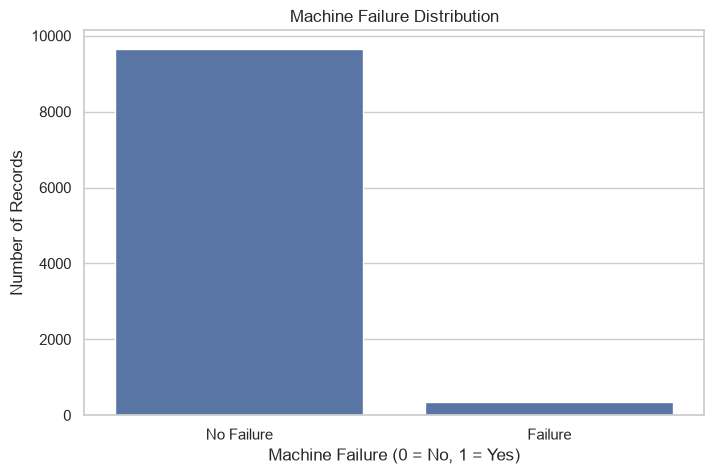

In [13]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Machine failure'
)

plt.title('Machine Failure Distribution')
plt.xlabel('Machine Failure (0 = No, 1 = Yes)')
plt.ylabel('Number of Records')

plt.xticks([0, 1], ['No Failure', 'Failure'])

plt.show()

# Analyse the five failure modes

In [14]:
failure_modes = ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']

failure_mode_counts = df[failure_modes].sum()

print(failure_mode_counts)

TWF     46
HDF    115
PWF     95
OSF     98
RNF     19
dtype: int64


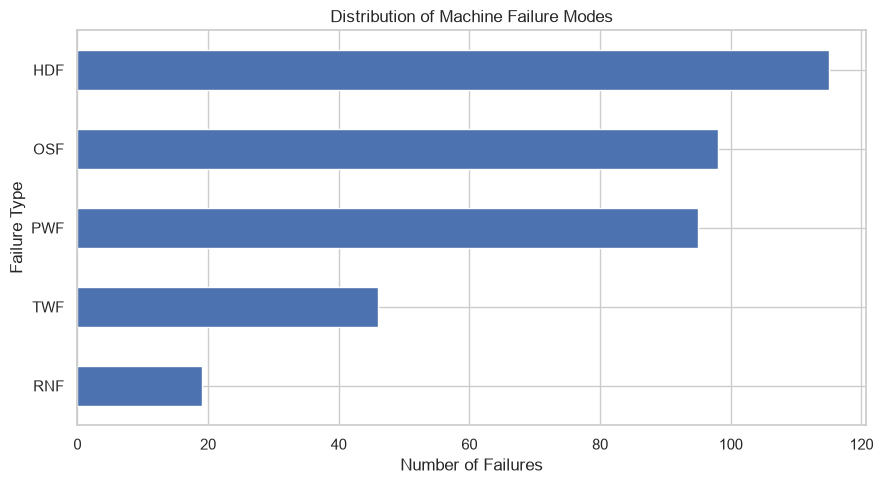

In [15]:
plt.figure(figsize=(9, 5))

failure_mode_counts.sort_values().plot(
    kind='barh'
)

plt.title('Distribution of Machine Failure Modes')
plt.xlabel('Number of Failures')
plt.ylabel('Failure Type')

plt.tight_layout()
plt.show()

# Temperature analysis

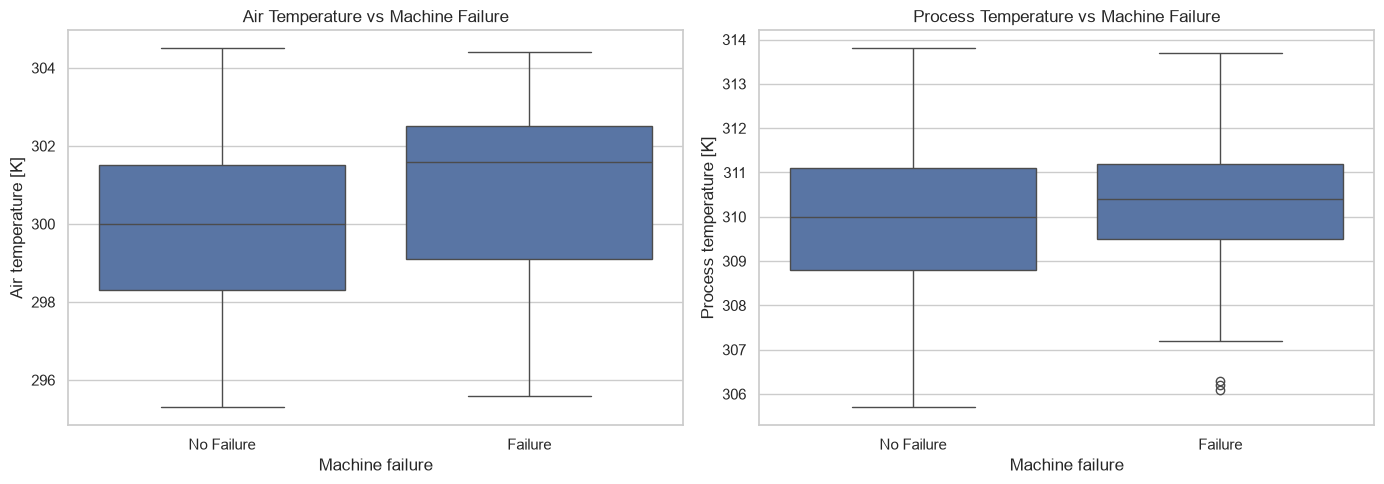

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=df,
    x='Machine failure',
    y='Air temperature [K]',
    ax=axes[0]
)

axes[0].set_title('Air Temperature vs Machine Failure')
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['No Failure', 'Failure'])

sns.boxplot(
    data=df,
    x='Machine failure',
    y='Process temperature [K]',
    ax=axes[1]
)

axes[1].set_title('Process Temperature vs Machine Failure')
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['No Failure', 'Failure'])

plt.tight_layout()
plt.show()

In [19]:
temperature_analysis = df.groupby(
    'Machine failure'
)[[
    'Air temperature [K]',
    'Process temperature [K]'
]].mean()

temperature_analysis.index = [
    'No Failure',
    'Failure'
]

temperature_analysis

,Air temperature [K],Process temperature [K]
No Failure,299.973999,309.995570
Failure,300.886431,310.290265


# Torque vs rotational speed

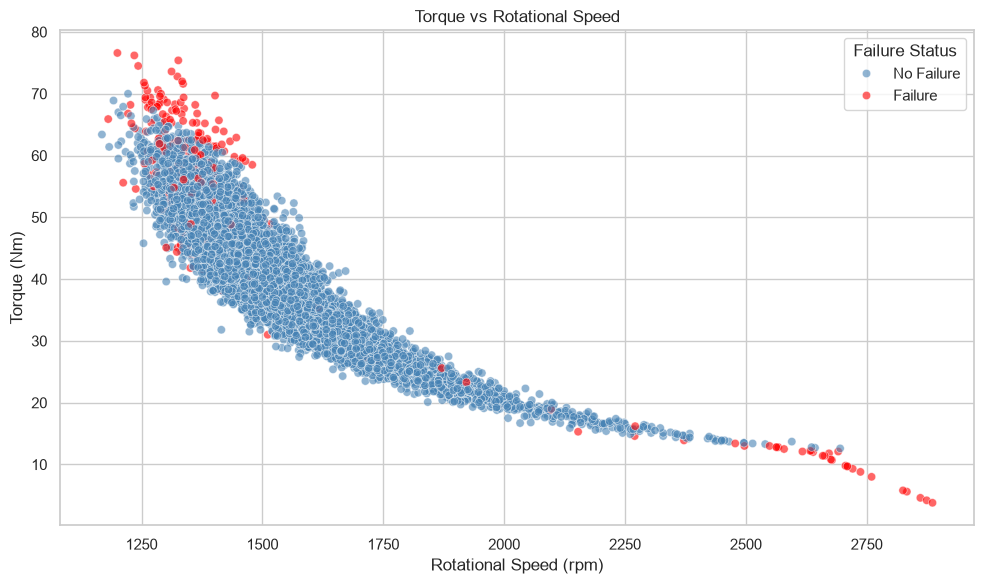

In [25]:
df['Failure Status'] = df['Machine failure'].map({
    0: 'No Failure',
    1: 'Failure'
})

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Rotational speed [rpm]',
    y='Torque [Nm]',
    hue='Failure Status',
    palette={
        'No Failure': 'steelblue',
        'Failure': 'red'
    },
    alpha=0.6
)

plt.title('Torque vs Rotational Speed')
plt.xlabel('Rotational Speed (rpm)')
plt.ylabel('Torque (Nm)')

plt.tight_layout()
plt.show()

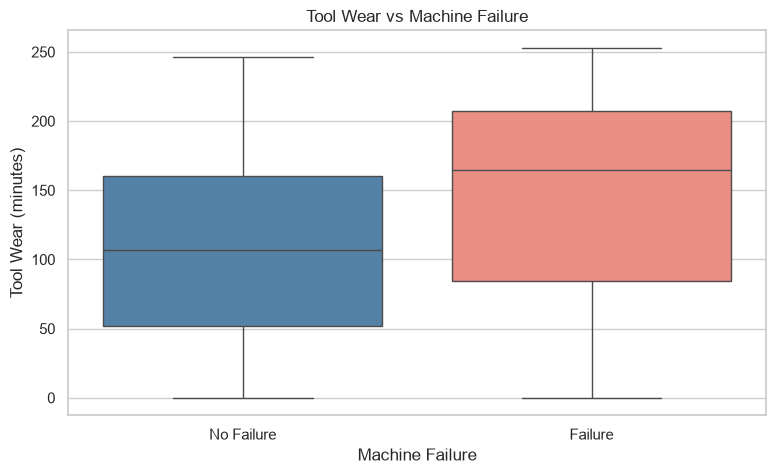

In [21]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='Machine failure',
    y='Tool wear [min]',
    hue='Machine failure',
    palette={0: 'steelblue', 1: 'salmon'},
    legend=False
)

plt.title('Tool Wear vs Machine Failure')
plt.xlabel('Machine Failure')
plt.ylabel('Tool Wear (minutes)')

plt.xticks([0, 1], ['No Failure', 'Failure'])

plt.show()

In [22]:
tool_wear_analysis = df.groupby(
    'Machine failure'
)['Tool wear [min]'].agg(
    ['mean', 'median', 'min', 'max']
)

tool_wear_analysis.index = [
    'No Failure',
    'Failure'
]

tool_wear_analysis

,mean,median,min,max
No Failure,106.693717,107.0,0,246
Failure,143.781711,165.0,0,253


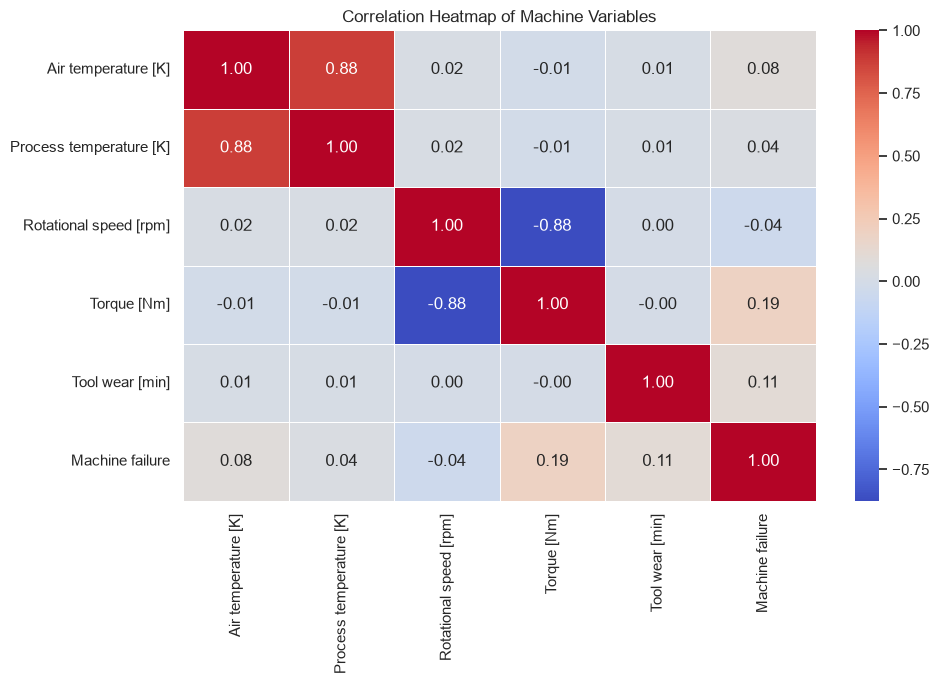

In [23]:
correlation_columns = [
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]',
    'Machine failure'
]

correlation_matrix = df[correlation_columns].corr()

# Plot heatmap

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Machine Variables')

plt.tight_layout()
plt.show()

# Data Preprocessing

In [26]:
df_ml = df.copy()

print("Original dataset:", df.shape)
print("ML dataset:", df_ml.shape)

Original dataset: (10000, 15)
ML dataset: (10000, 15)


In [27]:
# Remove unnecessary columns

columns_to_drop = [
    'UDI',
    'Product ID',
    'TWF',
    'HDF',
    'PWF',
    'OSF',
    'RNF',
    'Failure Status'
]

df_ml.drop(
    columns=columns_to_drop,
    inplace=True,
    errors='ignore'
)

print("Remaining columns:")
print(df_ml.columns.tolist())

print("\nNew dataset shape:", df_ml.shape)

Remaining columns:
['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure']

New dataset shape: (10000, 7)


### Tempature Difference

In [29]:
df_ml['Temperature Difference'] = (
    df_ml['Process temperature [K]']
    - df_ml['Air temperature [K]']
)

### Machine Power

In [30]:
df_ml['Machine Power'] = (
    df_ml['Torque [Nm]']
    * df_ml['Rotational speed [rpm]']
)

### Wear-Torque Interaction

In [31]:
df_ml['Wear Torque Interaction'] = (
    df_ml['Tool wear [min]']
    * df_ml['Torque [Nm]']
)

In [32]:
print(df_ml.head())
print("\nUpdated shape:", df_ml.shape)

  Type  Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  Machine failure  Temperature Difference  Machine Power  Wear Torque Interaction
0    M                298.1                    308.6                    1551         42.8                0                0                    10.5        66382.8                      0.0
1    L                298.2                    308.7                    1408         46.3                3                0                    10.5        65190.4                    138.9
2    L                298.1                    308.5                    1498         49.4                5                0                    10.4        74001.2                    247.0
3    L                298.2                    308.6                    1433         39.5                7                0                    10.4        56603.5                    276.5
4    L                298.2                    308.7        

In [33]:
# Encode categorical variable

df_ml = pd.get_dummies(
    df_ml,
    columns=['Type'],
    drop_first=True,
    dtype=int
)

print(df_ml.head())
print("\nUpdated shape:", df_ml.shape)

   Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  Machine failure  Temperature Difference  Machine Power  Wear Torque Interaction  Type_L  Type_M
0                298.1                    308.6                    1551         42.8                0                0                    10.5        66382.8                      0.0       0       1
1                298.2                    308.7                    1408         46.3                3                0                    10.5        65190.4                    138.9       1       0
2                298.1                    308.5                    1498         49.4                5                0                    10.4        74001.2                    247.0       1       0
3                298.2                    308.6                    1433         39.5                7                0                    10.4        56603.5                    276.5       1       0
4    

In [34]:
# Separate features and target

X = df_ml.drop(columns=['Machine failure'])

y = df_ml['Machine failure']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

Features shape: (10000, 10)
Target shape: (10000,)

Feature columns:
['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Temperature Difference', 'Machine Power', 'Wear Torque Interaction', 'Type_L', 'Type_M']


In [35]:
from sklearn.model_selection import train_test_split

# First split: 70% training, 30% temporary

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split: 15% validation, 15% testing

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Display dataset sizes

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (7000, 10)
Validation: (1500, 10)
Testing: (1500, 10)


In [36]:
# Check class distribution

print("TRAINING SET")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True) * 100)

print("\nVALIDATION SET")
print(y_val.value_counts())
print(y_val.value_counts(normalize=True) * 100)

print("\nTESTING SET")
print(y_test.value_counts())
print(y_test.value_counts(normalize=True) * 100)

TRAINING SET
Machine failure
0    6763
1     237
Name: count, dtype: int64
Machine failure
0    96.614286
1     3.385714
Name: proportion, dtype: float64

VALIDATION SET
Machine failure
0    1449
1      51
Name: count, dtype: int64
Machine failure
0    96.6
1     3.4
Name: proportion, dtype: float64

TESTING SET
Machine failure
0    1449
1      51
Name: count, dtype: int64
Machine failure
0    96.6
1     3.4
Name: proportion, dtype: float64


In [37]:
import os

os.makedirs("../results", exist_ok=True)

# Save processed dataset
df_ml.to_csv(
    "../results/processed_dataset.csv",
    index=False
)

# Save training, validation and testing sets
X_train.to_csv("../results/X_train.csv", index=False)
X_val.to_csv("../results/X_val.csv", index=False)
X_test.to_csv("../results/X_test.csv", index=False)

y_train.to_csv("../results/y_train.csv", index=False)
y_val.to_csv("../results/y_val.csv", index=False)
y_test.to_csv("../results/y_test.csv", index=False)

print("All datasets saved successfully!")

All datasets saved successfully!
